# NSL-KDD: EDA và preprocessing cho Autoencoder
Mục tiêu: kiểm tra dữ liệu, phân tích phân phối, chia validation và lưu pipeline.
Không huấn luyện mô hình hoặc chọn ngưỡng trên test ở giai đoạn này.

Nguồn: mirror Jehuty4949/NSL_KDD, commit `27bbbdf5c5cccf9970b8b6037a0f19dc09c5a0a9`.
Tham khảo: Tavallaee et al., *A Detailed Analysis of the KDD CUP 99 Data Set*, CISDA 2009.
Hai file raw được kiểm tra Git blob SHA-1 trước khi dùng; chỉ tải nếu chưa có.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'scripts/prepare_nsl_kdd.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'scripts/prepare_nsl_kdd.py').exists(), 'Mở notebook từ thư mục project hoặc notebooks'
sys.path.insert(0, str(ROOT / 'scripts'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from prepare_nsl_kdd import prepare, FEATURES, NUMERIC, CATEGORICAL
train, test, pipeline, arrays, metadata = prepare(ROOT)
pd.DataFrame(metadata['shapes'].items(), columns=['array', 'shape'])

Already verified: C:\Users\Admin\Documents\hoc-may-nc\data\raw\KDDTrain+.txt
Already verified: C:\Users\Admin\Documents\hoc-may-nc\data\raw\KDDTest+.txt


,array,shape
0,X_train,"[100778, 77]"
1,y_train,[100778]
2,group_train,[100778]
3,label_train,[100778]
4,row_train,[100778]
5,X_validation,"[25195, 77]"
6,y_validation,[25195]
7,group_validation,[25195]
8,label_validation,[25195]
9,row_validation,[25195]


## Kiểm tra chất lượng và phân bố nhãn
41 đặc trưng gồm 38 số và 3 categorical. Nhãn và difficulty luôn bị loại khỏi đầu vào.
Row ID trong file NPZ là chỉ số dòng bắt đầu từ 0 trong file raw tương ứng.

,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty,group,is_attack
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.00,0.00,0.00,0.05,0.00,normal,20,normal,0
1,0,udp,other,SF,146,0,0,0,0,0,...,0.88,0.00,0.00,0.00,0.00,0.00,normal,15,normal,0
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19,DoS,1
3,0,tcp,http,SF,232,8153,0,0,0,0,...,0.03,0.04,0.03,0.01,0.00,0.01,normal,21,normal,0
4,0,tcp,http,SF,199,420,0,0,0,0,...,0.00,0.00,0.00,0.00,0.00,0.00,normal,21,normal,0


,rows,missing,duplicate_records,duplicate_features,attack_ratio
train,125973.0,0.0,0.0,16.0,0.465417
test,22544.0,0.0,0.0,57.0,0.569242


,train,test
group,,
DoS,45927,7460
Probe,11656,2421
R2L,995,2885
U2R,52,67
normal,67343,9711


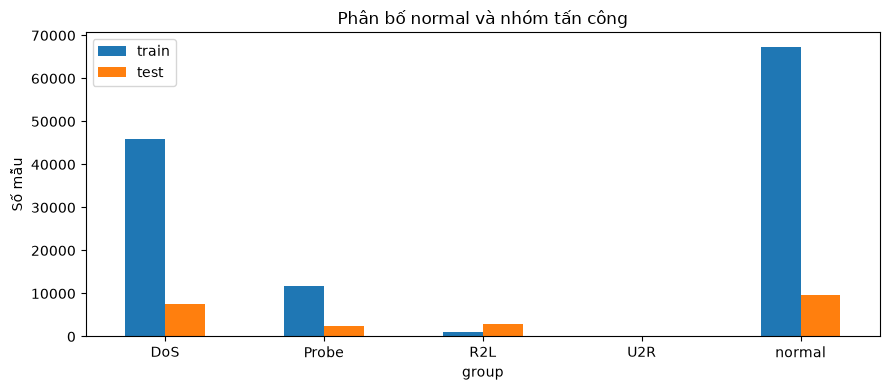

,count,mean,std,min,25%,50%,75%,max
duration,125973.0,287.144650,2.604515e+03,0.0,0.00,0.00,0.00,4.290800e+04
src_bytes,125973.0,45566.743000,5.870331e+06,0.0,0.00,44.00,276.00,1.379964e+09
dst_bytes,125973.0,19779.114421,4.021269e+06,0.0,0.00,0.00,516.00,1.309937e+09
land,125973.0,0.000198,1.408607e-02,0.0,0.00,0.00,0.00,1.000000e+00
wrong_fragment,125973.0,0.022687,2.535300e-01,0.0,0.00,0.00,0.00,3.000000e+00
urgent,125973.0,0.000111,1.436603e-02,0.0,0.00,0.00,0.00,3.000000e+00
hot,125973.0,0.204409,2.149968e+00,0.0,0.00,0.00,0.00,7.700000e+01
num_failed_logins,125973.0,0.001222,4.523914e-02,0.0,0.00,0.00,0.00,5.000000e+00
logged_in,125973.0,0.395736,4.890101e-01,0.0,0.00,0.00,1.00,1.000000e+00
num_compromised,125973.0,0.279250,2.394204e+01,0.0,0.00,0.00,0.00,7.479000e+03


In [2]:
display(train.head())
quality = pd.DataFrame({name: {
    'rows': len(df), 'missing': int(df.isna().sum().sum()),
    'duplicate_records': int(df.duplicated(subset=[*FEATURES, 'label', 'difficulty']).sum()),
    'duplicate_features': int(df.duplicated(subset=list(FEATURES)).sum()),
    'attack_ratio': df.is_attack.mean(),
} for name, df in [('train', train), ('test', test)]}).T
display(quality)
counts = pd.DataFrame({'train': train.group.value_counts(), 'test': test.group.value_counts()}).fillna(0).astype(int)
display(counts)
counts.plot.bar(figsize=(9, 4), title='Phân bố normal và nhóm tấn công')
plt.ylabel('Số mẫu'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()
display(train[list(NUMERIC)].describe().T)

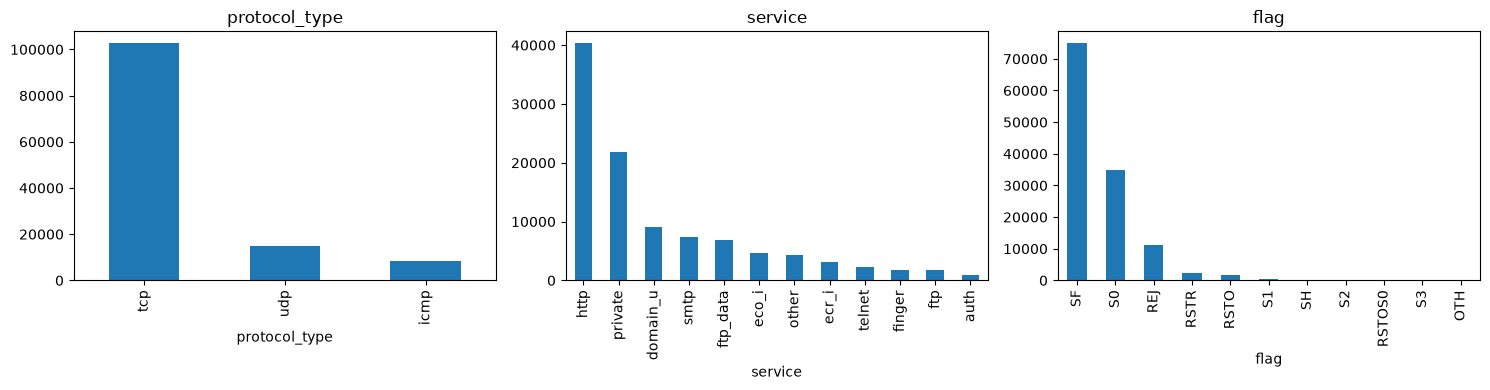

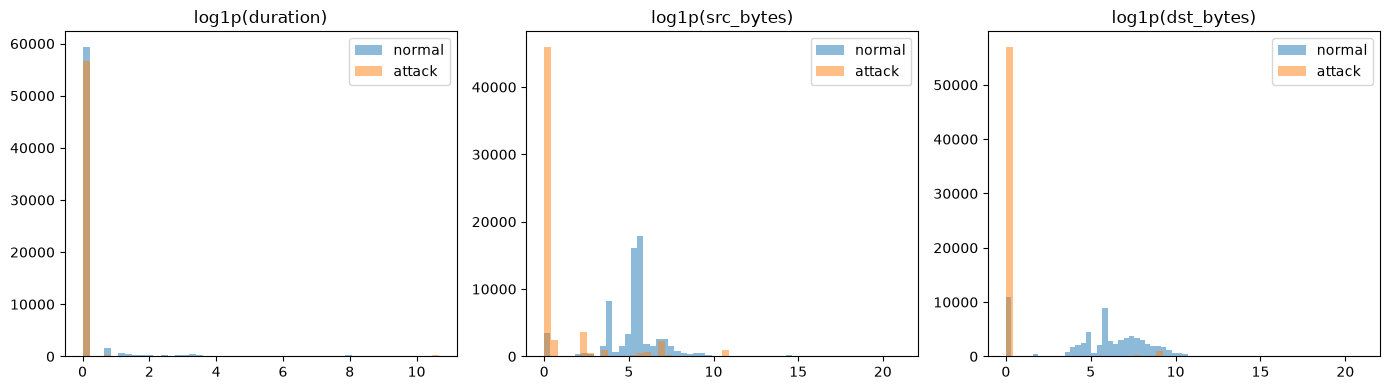

,constant_train,min,max
duration,False,0.0,4.290800e+04
src_bytes,False,0.0,1.379964e+09
dst_bytes,False,0.0,1.309937e+09
land,False,0.0,1.000000e+00
wrong_fragment,False,0.0,3.000000e+00
urgent,False,0.0,3.000000e+00
hot,False,0.0,7.700000e+01
num_failed_logins,False,0.0,5.000000e+00
logged_in,False,0.0,1.000000e+00
num_compromised,False,0.0,7.479000e+03


Nhãn chỉ có trong test: ['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(CATEGORICAL, axes):
    train[col].value_counts().head(12).plot.bar(ax=ax, title=col)
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(['duration', 'src_bytes', 'dst_bytes'], axes):
    for label, frame in train.groupby('is_attack'):
        ax.hist(np.log1p(frame[col]), bins=50, alpha=0.5, label='attack' if label else 'normal')
    ax.set_title('log1p(' + col + ')'); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame({
    'constant_train': train[list(NUMERIC)].nunique().eq(1),
    'min': train[list(NUMERIC)].min(), 'max': train[list(NUMERIC)].max(),
}))
print('Nhãn chỉ có trong test:', sorted(set(test.label) - set(train.label)))

## Quy tắc preprocessing
- Tách 80/20 từ KDDTrain+, stratify theo nhãn nhị phân, seed=42; giữ nguyên KDDTest+.
- Fit StandardScaler và OneHotEncoder chỉ trên normal của phần train.
- Category lạ tạo block one-hot bằng 0; thống kê bên dưới giúp nhận biết giới hạn này.
- StandardScaler giữ giá trị ngoài miền train, không clip. Đầu ra AE sau này nên dùng linear,
  không dùng sigmoid. Các biến có đuôi dài có thể chi phối MSE; log1p chỉ dùng cho EDA ở đây.
- Giữ đặc trưng hằng để schema ổn định; không tự loại trùng vì đang giữ giao thức benchmark.
  EDA test chỉ mô tả; không dùng để chọn biến, scaler hoặc ngưỡng.
- Dùng X_train_normal để huấn luyện AE; X_validation_normal cho early stopping/ngưỡng.
  Các mảng train đầy đủ được giữ để baseline có giám sát có thể dùng cùng phép chia.

In [4]:
encoder = pipeline.named_steps['features'].named_transformers_['categorical']
unknown = []
for split in ['train', 'validation', 'test']:
    frame = train.loc[arrays['row_' + split]] if split != 'test' else test
    for col, categories in zip(CATEGORICAL, encoder.categories_):
        unknown.append({'split': split, 'feature': col,
                        'unknown_rows': int((~frame[col].isin(categories)).sum())})
display(pd.DataFrame(unknown))
assert set(arrays['row_train']).isdisjoint(arrays['row_validation'])
assert len(arrays['row_train']) + len(arrays['row_validation']) == len(train)
assert len(arrays['X_test']) == len(test)
assert arrays['X_train_normal'].shape[0] == (arrays['y_train'] == 0).sum()
for key, value in arrays.items():
    if key.startswith('X_'):
        assert value.dtype == np.float32 and np.isfinite(value).all()
normal = train.loc[arrays['row_train']].query('is_attack == 0')
np.testing.assert_allclose(
    pipeline.named_steps['features'].named_transformers_['numeric'].mean_,
    normal[NUMERIC].mean().to_numpy(),
)
print('Kiểm tra chia tập, normal-only fit và ma trận hữu hạn: PASS')
print('Số chiều sau encode:', len(metadata['features']))

,split,feature,unknown_rows
0,train,protocol_type,0
1,train,service,14584
2,train,flag,82
3,validation,protocol_type,0
4,validation,service,3562
5,validation,flag,21
6,test,protocol_type,0
7,test,service,1343
8,test,flag,2


Kiểm tra chia tập, normal-only fit và ma trận hữu hạn: PASS
Số chiều sau encode: 77


In [5]:
import joblib
saved = joblib.load(ROOT / 'artifacts/preprocessing/pipeline.joblib')
unseen = test.loc[:0, list(FEATURES)].copy()
unseen['service'] = '__unseen_service__'
assert np.isfinite(saved.transform(unseen)).all()
np.testing.assert_allclose(saved.transform(test.loc[:19, list(FEATURES)]),
                           arrays['X_test'][:20], rtol=1e-6, atol=1e-6)
with np.load(ROOT / 'data/processed/nsl_kdd.npz', allow_pickle=False) as stored:
    np.testing.assert_array_equal(stored['X_train_normal'], arrays['X_train_normal'])
print('Lưu/nạp pipeline và dữ liệu: PASS')
display(pd.DataFrame({'feature': metadata['features']}))

Lưu/nạp pipeline và dữ liệu: PASS


,feature
0,numeric__duration
1,numeric__src_bytes
2,numeric__dst_bytes
3,numeric__land
4,numeric__wrong_fragment
...,...
72,categorical__flag_S1
73,categorical__flag_S2
74,categorical__flag_S3
75,categorical__flag_SF


## Đầu ra và bước tiếp theo
Pipeline: `../artifacts/preprocessing/pipeline.joblib`; metadata: cùng thư mục.
Dữ liệu: `../data/processed/nsl_kdd.npz`, gồm ma trận float32, nhãn, nhóm và row ID.
Chỉ nạp joblib từ nguồn tin cậy. Phiên bản thư viện được ghi trong metadata và requirements-lock.txt.
NSL-KDD là benchmark cũ; mất cân bằng và nhãn tấn công mới trong test cần được tính đến
khi báo cáo kết quả. Chưa có kết luận về khả năng phát hiện hoặc điểm rủi ro trước khi huấn luyện.